In [1]:
from pathlib import Path
from fastai.vision.all import *

searches = 'dog', 'other'
path = Path('/kaggle/input/datasets/danielshanbalico/dog-vs-not-dog/Dog vs Not-Dog')

# for o in searches:
#     src = path/o
#     dest = path/f"{o}"
#     resize_images(src, max_size=400, dest=dest)

In [2]:
from sklearn.model_selection import train_test_split

path = Path('/kaggle/input/datasets/danielshanbalico/dog-vs-not-dog/Dog vs Not-Dog')
files = get_image_files(path)
train_files, test_files = train_test_split(
    files,
    test_size=0.2,
    random_state=29)
print(len(train_files))
print(len(test_files))

20099
5025


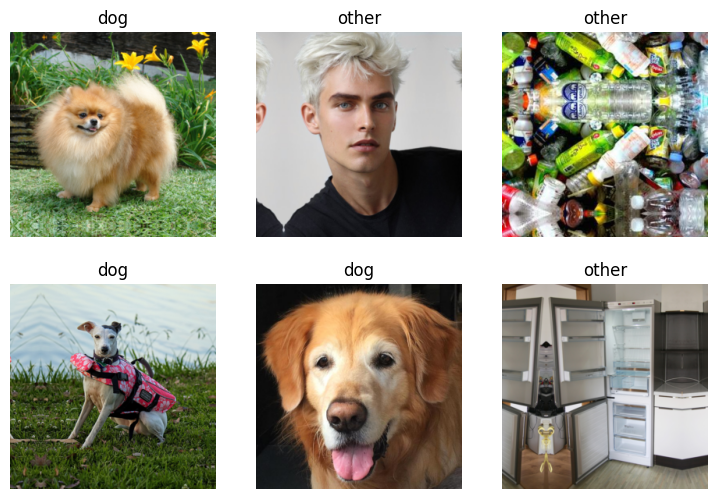

In [3]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock),
    get_items=noop,
    splitter=RandomSplitter(valid_pct=0.2, seed=29),
    get_y=parent_label,
    item_tfms=[Resize(264, method='pad', pad_mode='reflection')]
).dataloaders(train_files, bs=128)
import matplotlib.pyplot as plt
plt.style.use("default")
dls.show_batch(max_n=6)

In [4]:
learn = vision_learner(dls, 
                       'convnext_tiny',
                       loss_func=CrossEntropyLossFlat(), 
                       metrics=error_rate, 
                       wd=0.1).to_fp16()
plt.style.use("dark_background")
learn.fine_tune(4, base_lr=1e-2)

model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

epoch,train_loss,valid_loss,error_rate,time
0,0.045963,0.009627,0.003235,03:17


epoch,train_loss,valid_loss,error_rate,time
0,0.031540,0.064938,0.017168,02:48
1,0.020896,0.029461,0.007465,02:42
2,0.005399,0.002554,0.000746,02:47
3,0.001093,0.002875,0.000746,02:43


In [5]:
test_dl = dls.test_dl(test_files, with_labels=True)
loss, err = learn.validate(dl=test_dl)
accuracy = (1-err)*100
print(f"Test Images: {len(test_files)}")
print(f"Correct Predictions: {round(accuracy*len(test_files)/100)}")
print(f"Incorrect Predictions: {len(test_files)-round(accuracy*len(test_files)/100)}")
print(f"Accuracy: {accuracy:.2f}%")

Test Images: 5025
Correct Predictions: 5018
Incorrect Predictions: 7
Accuracy: 99.86%


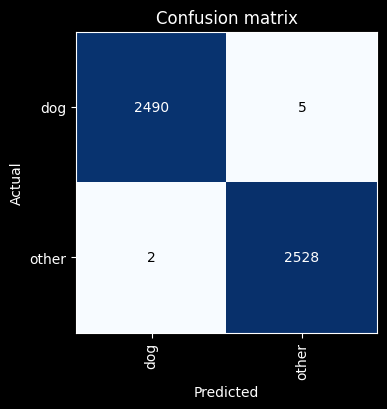

In [6]:
interp = ClassificationInterpretation.from_learner(
    learn,
    dl=test_dl)
interp.plot_confusion_matrix(figsize=(4,4))

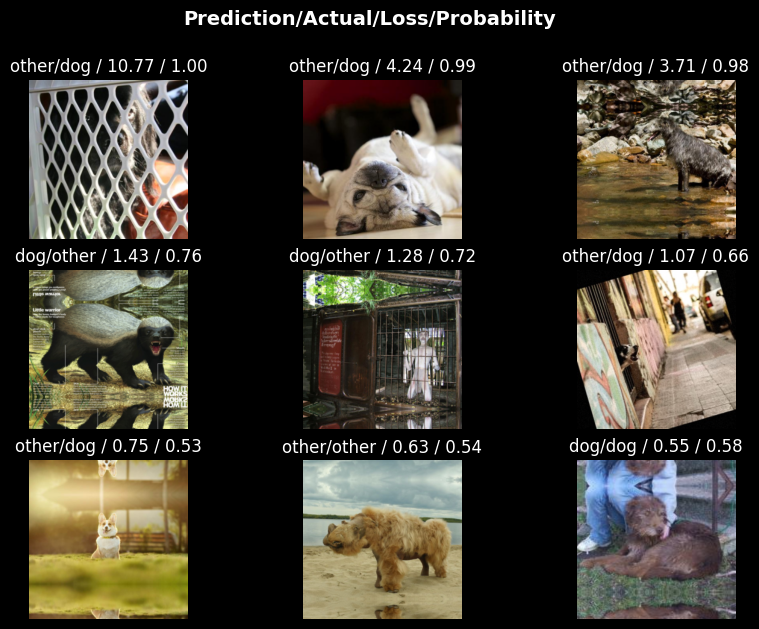

In [7]:
interp.plot_top_losses(9, figsize=(10,7))

In [8]:
from sklearn.metrics import classification_report

preds, targs = learn.get_preds(dl=test_dl)

y_pred = preds.argmax(dim=1).numpy()
y_true = targs.numpy()

print(classification_report(
    y_true,
    y_pred,
    target_names=dls.vocab
))

              precision    recall  f1-score   support

         dog       1.00      1.00      1.00      2495
       other       1.00      1.00      1.00      2530

    accuracy                           1.00      5025
   macro avg       1.00      1.00      1.00      5025
weighted avg       1.00      1.00      1.00      5025



In [10]:
learn.export('dog_or_not_convnext_tiny.pkl')